In [22]:
from pathlib import Path
import time

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from skimage.feature import canny
from IPython.display import display

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("scikit-image:", __import__("skimage").__version__)

OpenCV: 4.12.0
NumPy: 2.2.6
scikit-image: 0.25.2


## 2. Chuẩn bị dữ liệu

Xác định đường dẫn thư mục dữ liệu và thư mục lưu kết quả để phục vụ các thí nghiệm Canny.

In [23]:
from pathlib import Path

def find_lab2_dir():
    current = Path.cwd().resolve()

    # Tìm thư mục lab_2 từ thư mục hiện tại và các thư mục cha
    for folder in (current, *current.parents):
        if folder.name.lower() == "lab_2":
            return folder

        candidate = folder / "lab_2"
        if candidate.is_dir():
            return candidate

    raise FileNotFoundError(
        "Không tìm thấy thư mục lab_2. "
        "Vui lòng kiểm tra vị trí notebook."
    )


LAB2_DIR = find_lab2_dir()
DATA_DIR = LAB2_DIR / "data"
FIGURE_DIR = LAB2_DIR / "result" / "figures" / "tv2_parameters"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Data tồn tại:", DATA_DIR.exists())
print("Số thư mục ảnh đầu vào:", (DATA_DIR / "input").is_dir())
print("Thư mục lưu kết quả:", FIGURE_DIR.relative_to(LAB2_DIR))

Data tồn tại: True
Số thư mục ảnh đầu vào: True
Thư mục lưu kết quả: result\figures\tv2_parameters


In [24]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

image_paths = sorted(
    path
    for path in DATA_DIR.rglob("*")
    if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
)

print(f"Tổng số ảnh tìm thấy: {len(image_paths)}")

for i, path in enumerate(image_paths, start=1):
    print(f"{i}. {path.relative_to(LAB2_DIR)}")

Tổng số ảnh tìm thấy: 50
1. data\input\01_hinh_hoc_ro_net.png
2. data\input\02_tuong_phan_thap.png
3. data\input\03_nhieu_gaussian.png
4. data\input\04_anh_that_nhieu_chi_tiet.png
5. data\input\05_dong_xu_phan_doan.png
6. data\input\06_chan_dung_mau.png
7. data\input\07_anh_bi_mo.png
8. data\input\08_nhieu_doi_tuong.png
9. data\input\09_tang_tuong_phan_01.png
10. data\input\10_tang_tuong_phan_02.png
11. data\input\11_tang_tuong_phan_03.png
12. data\input\12_tang_tuong_phan_04.png
13. data\input\13_tang_tuong_phan_05.png
14. data\input\14_tang_tuong_phan_06.png
15. data\input\15_giam_tuong_phan_01.png
16. data\input\16_giam_tuong_phan_02.png
17. data\input\17_giam_tuong_phan_03.png
18. data\input\18_giam_tuong_phan_04.png
19. data\input\19_giam_tuong_phan_05.png
20. data\input\20_giam_tuong_phan_06.png
21. data\input\21_nhieu_gaussian_01.png
22. data\input\22_nhieu_gaussian_02.png
23. data\input\23_nhieu_gaussian_03.png
24. data\input\24_nhieu_gaussian_04.png
25. data\input\25_nhieu_gau

Chọn 2 ảnh để xử lý

In [25]:
selected_images = [
    DATA_DIR / "input" / "01_hinh_hoc_ro_net.png",
    DATA_DIR / "input" / "02_tuong_phan_thap.png",
]

images = {}

for path in selected_images:
    gray = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

    if gray is None:
        raise ValueError(f"Không đọc được ảnh: {path}")

    images[path.name] = gray

print("Số ảnh đã đọc:", len(images))
print("Tên ảnh:", list(images.keys()))

Số ảnh đã đọc: 2
Tên ảnh: ['01_hinh_hoc_ro_net.png', '02_tuong_phan_thap.png']


## 4. Thiết lập cấu hình Baseline

Baseline là cấu hình Canny ban đầu được sử dụng làm mốc so sánh với các cấu hình khác. Trong thí nghiệm này, sigma được đặt bằng 1.0, ngưỡng thấp bằng 0.1 và ngưỡng cao bằng 0.2.

Kết quả gồm ảnh gốc, ảnh biên sau xử lý và bảng thống kê số pixel biên cùng tỷ lệ pixel biên trên tổng số pixel của ảnh.

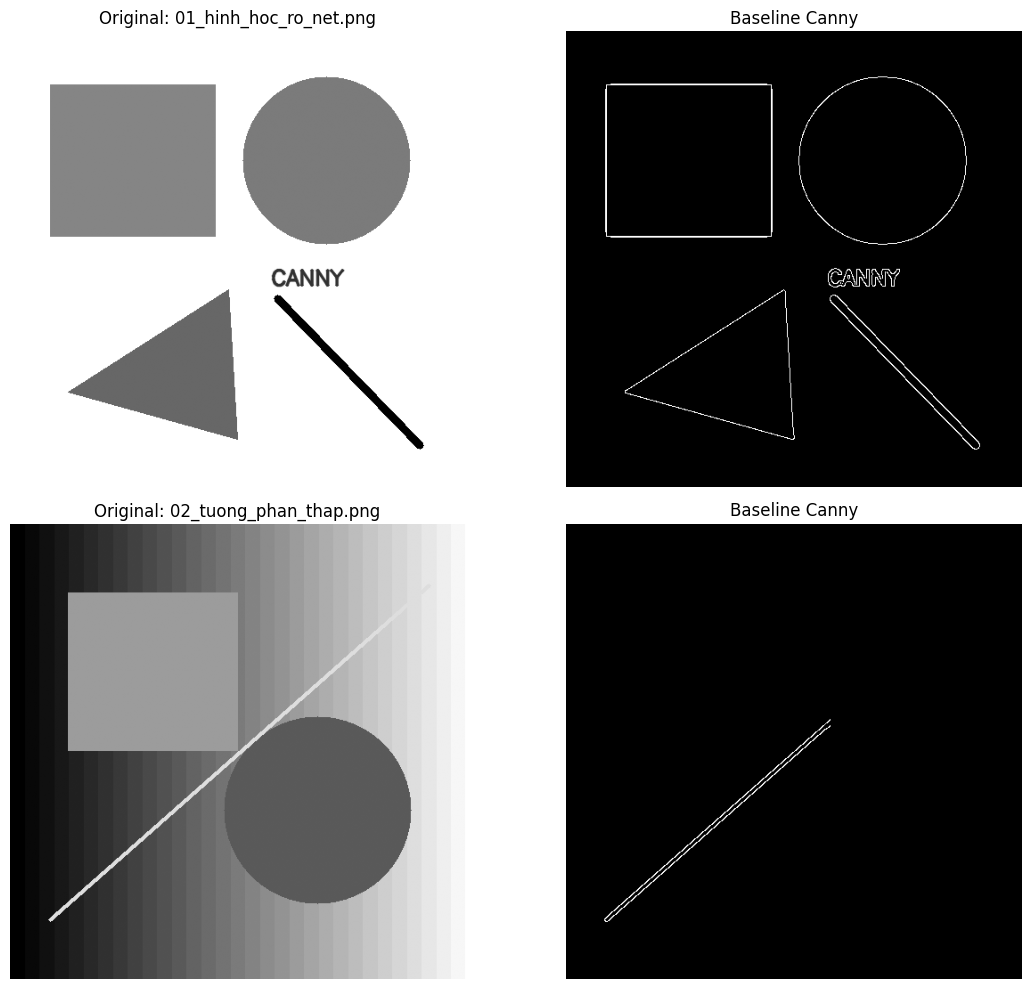

,image_name,sigma,low_threshold,high_threshold,edge_pixels,edge_ratio_percent
0,01_hinh_hoc_ro_net.png,1.0,0.1,0.2,3755,1.432
1,02_tuong_phan_thap.png,1.0,0.1,0.2,892,0.340


In [26]:
# Baseline Canny
BASELINE_SIGMA = 1.0
BASELINE_LOW = 0.1
BASELINE_HIGH = 0.2

baseline_results = []

fig, axes = plt.subplots(len(images), 2, figsize=(12, 5 * len(images)))

for row, (name, gray) in enumerate(images.items()):
    edges = canny(
        gray.astype(np.float32) / 255.0,
        sigma=BASELINE_SIGMA,
        low_threshold=BASELINE_LOW,
        high_threshold=BASELINE_HIGH
    )

    axes[row, 0].imshow(gray, cmap="gray")
    axes[row, 0].set_title(f"Original: {name}")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(edges, cmap="gray")
    axes[row, 1].set_title("Baseline Canny")
    axes[row, 1].axis("off")

    baseline_results.append({
        "image_name": name,
        "sigma": BASELINE_SIGMA,
        "low_threshold": BASELINE_LOW,
        "high_threshold": BASELINE_HIGH,
        "edge_pixels": int(np.count_nonzero(edges)),
        "edge_ratio_percent": round(float(edges.mean() * 100), 3)
    })

plt.tight_layout()
plt.savefig(FIGURE_DIR / "01_baseline.png", dpi=200, bbox_inches="tight")
plt.show()

baseline_df = pd.DataFrame(baseline_results)
display(baseline_df)

### Nhận xét kết quả Baseline

Baseline được sử dụng làm cấu hình tham chiếu cho các thí nghiệm tiếp theo, với `sigma = 1.0`, `low_threshold = 0.1` và `high_threshold = 0.2`.

Kết quả trên hai ảnh cho phép quan sát khả năng phát hiện đường biên ban đầu của thuật toán Canny. Số lượng pixel biên và tỷ lệ pixel biên giúp mô tả mức độ phát hiện biên, nhưng không trực tiếp phản ánh độ chính xác của các đường biên.

- **Ảnh hình học rõ nét:** Quan sát xem các cạnh của hình có được phát hiện liên tục, rõ ràng hay không; đồng thời kiểm tra các đường biên thừa do nhiễu.
- **Ảnh có độ tương phản thấp:** Quan sát xem thuật toán có phát hiện được các đường biên quan trọng hay bỏ sót những vùng chuyển tiếp cường độ sáng không rõ ràng.

Kết quả Baseline là cơ sở để đánh giá sự thay đổi khi điều chỉnh sigma và ngưỡng Canny ở các thí nghiệm tiếp theo.

## 4. Khảo sát anh hưởng của sigma

Thử nghiệm các giá trị sigma khác nhau trên 2 ảnh gốc để quan sát sự thay đổi của kết quả phát hiện biên.

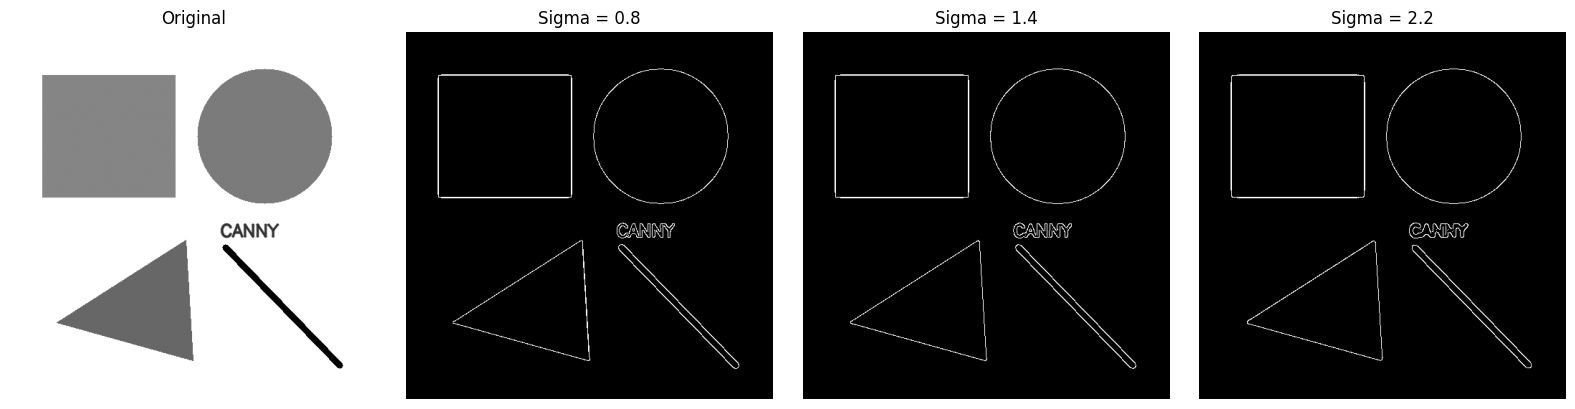

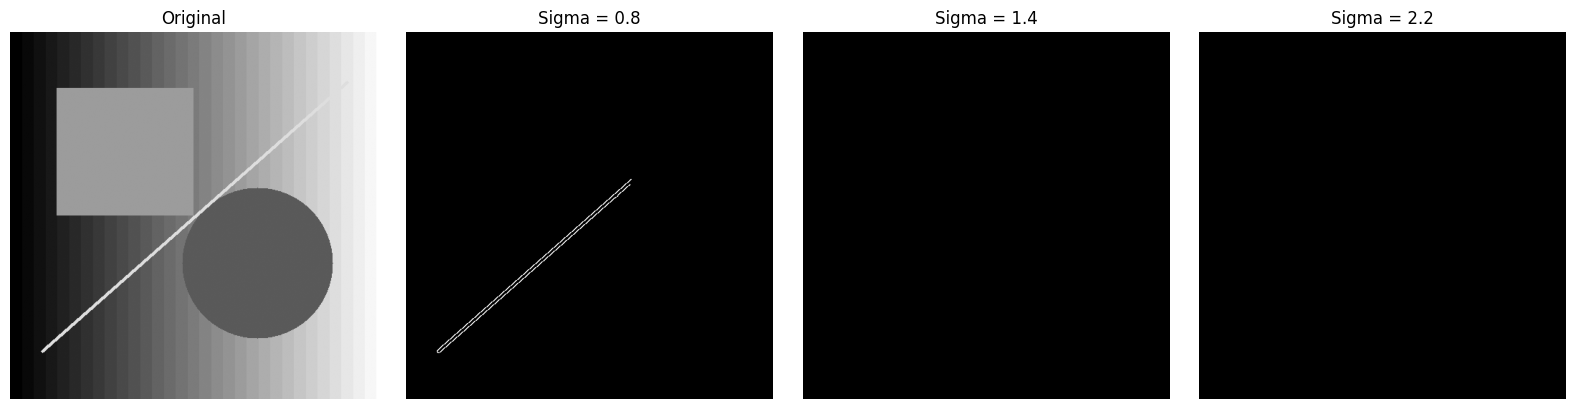

,image_name,sigma,edge_pixels,edge_ratio_percent
0,01_hinh_hoc_ro_net.png,0.8,3848,1.468
1,01_hinh_hoc_ro_net.png,1.4,3736,1.425
2,01_hinh_hoc_ro_net.png,2.2,3695,1.410
3,02_tuong_phan_thap.png,0.8,956,0.365
4,02_tuong_phan_thap.png,1.4,0,0.000
5,02_tuong_phan_thap.png,2.2,0,0.000


In [27]:
SIGMA_VALUES = [0.8, 1.4, 2.2]

sigma_results = []

for name, gray in images.items():
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))

    axes[0].imshow(gray, cmap="gray")
    axes[0].set_title("Original")
    axes[0].axis("off")

    for i, sigma in enumerate(SIGMA_VALUES, start=1):
        edges = canny(
            gray.astype(np.float32) / 255.0,
            sigma=sigma,
            low_threshold=BASELINE_LOW,
            high_threshold=BASELINE_HIGH
        )

        sigma_results.append({
            "image_name": name,
            "sigma": sigma,
            "edge_pixels": int(np.count_nonzero(edges)),
            "edge_ratio_percent": round(float(edges.mean() * 100), 3)
        })

        axes[i].imshow(edges, cmap="gray")
        axes[i].set_title(f"Sigma = {sigma}")
        axes[i].axis("off")

    plt.tight_layout()
    plt.savefig(
        FIGURE_DIR / f"sigma_{Path(name).stem}.png",
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()

sigma_df = pd.DataFrame(sigma_results)
display(sigma_df)

sigma_df.to_csv(
    FIGURE_DIR / "sigma_results.csv",
    index=False,
    encoding="utf-8-sig"
)

### Phân tích kết quả thay đổi Sigma

Trong thí nghiệm này, ba giá trị `sigma = 0.8`, `1.4` và `2.2` được thử nghiệm, trong khi hai ngưỡng Canny được giữ cố định ở mức `low_threshold = 0.1` và `high_threshold = 0.2`.

Sigma điều khiển mức độ làm trơn ảnh trước khi phát hiện biên. Khi sigma tăng, ảnh được làm trơn mạnh hơn, giúp giảm một phần nhiễu nhưng cũng có thể làm mất các chi tiết nhỏ.

- **Sigma = 0.8:** Làm trơn nhẹ, có khả năng giữ được nhiều chi tiết nhưng có thể phát hiện thêm các đường biên không mong muốn.
- **Sigma = 1.4:** Làm trơn ở mức trung bình, cần đánh giá khả năng cân bằng giữa giữ chi tiết và giảm nhiễu.
- **Sigma = 2.2:** Làm trơn mạnh hơn, có thể loại bỏ một số biên nhỏ hoặc làm các chi tiết gần nhau khó phân biệt.

Cần so sánh trực tiếp các ảnh đầu ra để xác định giá trị sigma phù hợp với từng ảnh. Không thể kết luận sigma lớn hơn luôn tốt hơn, vì hiệu quả phụ thuộc vào đặc điểm ảnh và mục tiêu phát hiện biên.

## 5. Ảnh hưởng của ngưỡng Canny

Thay đổi các cặp ngưỡng thấp và cao, đồng thời giữ sigma cố định để so sánh kết quả phát hiện biên.

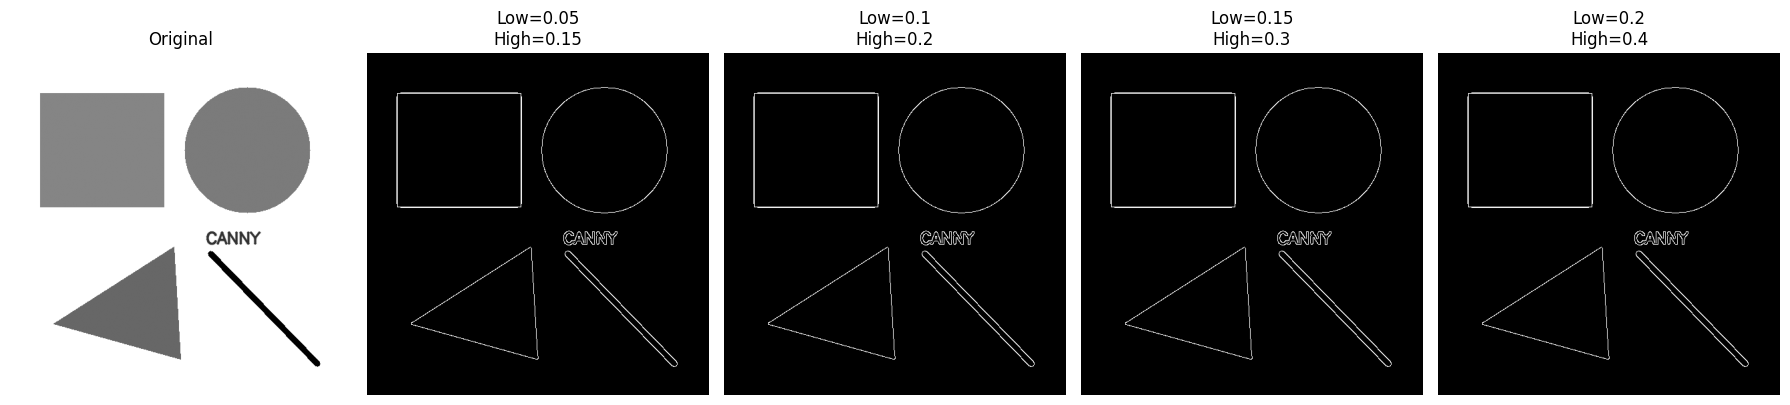

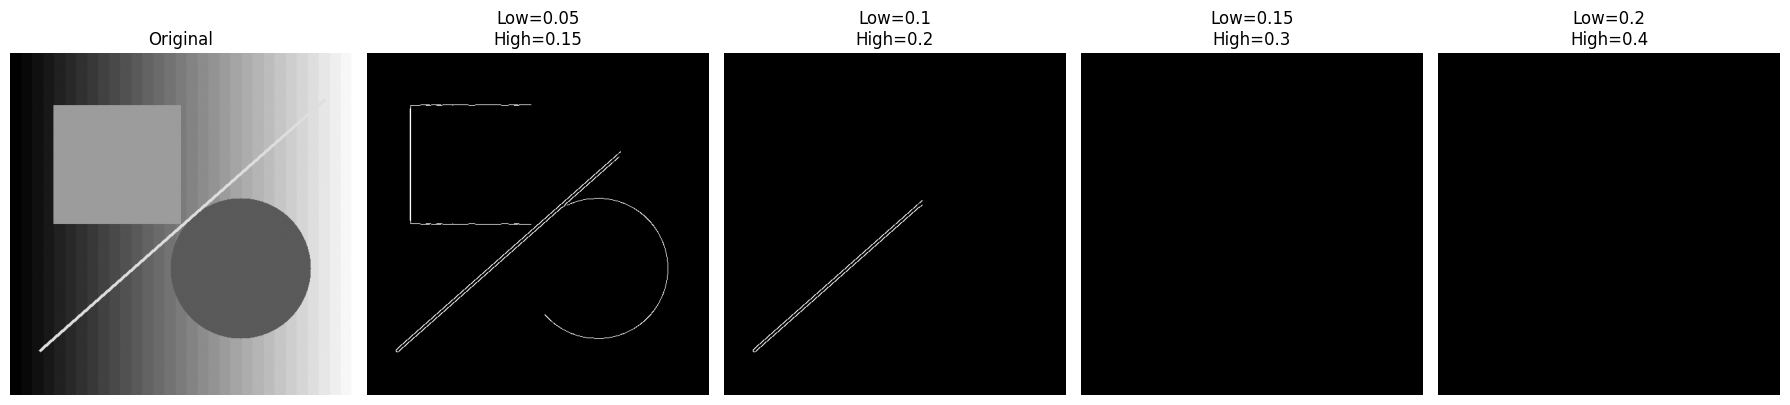

,image_name,low_threshold,high_threshold,edge_pixels,edge_ratio_percent
0,01_hinh_hoc_ro_net.png,0.05,0.15,3755,1.432
1,01_hinh_hoc_ro_net.png,0.10,0.20,3755,1.432
2,01_hinh_hoc_ro_net.png,0.15,0.30,3755,1.432
3,01_hinh_hoc_ro_net.png,0.20,0.40,3755,1.432
4,02_tuong_phan_thap.png,0.05,0.15,2426,0.925
5,02_tuong_phan_thap.png,0.10,0.20,892,0.340
6,02_tuong_phan_thap.png,0.15,0.30,0,0.000
7,02_tuong_phan_thap.png,0.20,0.40,0,0.000


In [28]:
THRESHOLD_PAIRS = [
    (0.05, 0.15),
    (0.10, 0.20),
    (0.15, 0.30),
    (0.20, 0.40)
]

threshold_results = []

for name, gray in images.items():
    fig, axes = plt.subplots(1, 5, figsize=(18, 4))

    axes[0].imshow(gray, cmap="gray")
    axes[0].set_title("Original")
    axes[0].axis("off")

    for i, (low, high) in enumerate(THRESHOLD_PAIRS, start=1):
        edges = canny(
            gray.astype(np.float32) / 255.0,
            sigma=BASELINE_SIGMA,
            low_threshold=low,
            high_threshold=high
        )

        threshold_results.append({
            "image_name": name,
            "low_threshold": low,
            "high_threshold": high,
            "edge_pixels": int(np.count_nonzero(edges)),
            "edge_ratio_percent": round(float(edges.mean() * 100), 3)
        })

        axes[i].imshow(edges, cmap="gray")
        axes[i].set_title(f"Low={low}\nHigh={high}")
        axes[i].axis("off")

    plt.tight_layout()
    plt.savefig(
        FIGURE_DIR / f"thresholds_{Path(name).stem}.png",
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df)

threshold_df.to_csv(
    FIGURE_DIR / "threshold_results.csv",
    index=False,
    encoding="utf-8-sig"
)

###  Phân tích kết quả thay đổi ngưỡng

Thí nghiệm sử dụng bốn cặp ngưỡng `(0.05, 0.15)`, `(0.10, 0.20)`, `(0.15, 0.30)` và `(0.20, 0.40)`. Trong quá trình thử nghiệm, sigma được giữ cố định ở mức `1.0`.

Canny sử dụng hai ngưỡng để phân loại và liên kết các điểm biên. Ngưỡng cao ảnh hưởng đến việc xác định các điểm biên mạnh; ngưỡng thấp hỗ trợ xác định các điểm biên yếu có liên kết với biên mạnh.

- **Ngưỡng thấp:** Có thể giữ lại nhiều đường biên hơn, nhưng cũng có nguy cơ xuất hiện nhiều biên do nhiễu.
- **Ngưỡng trung bình:** Cần quan sát mức độ giữ lại các đường biên quan trọng và khả năng loại bỏ các đường biên không cần thiết.
- **Ngưỡng cao:** Có thể giảm các đường biên yếu, nhưng có nguy cơ bỏ sót những đường biên thực sự có cường độ thấp.

Khi đánh giá, cần kết hợp hình ảnh trực quan với bảng số lượng pixel biên và tỷ lệ pixel biên. Cấu hình phù hợp là cấu hình giữ được các đường biên quan trọng, hạn chế biên giả và không làm mất quá nhiều chi tiết cần thiết.

## 6. So sánh Canny và Auto-Canny

So sánh kết quả sử dụng ngưỡng thủ công với Auto-Canny trên hai ảnh gốc.

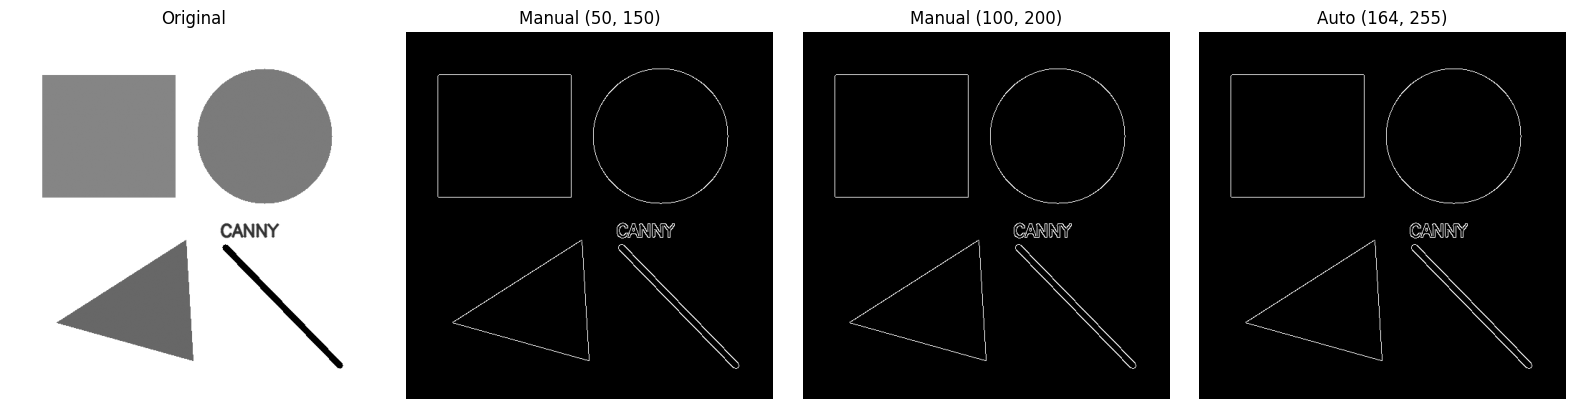

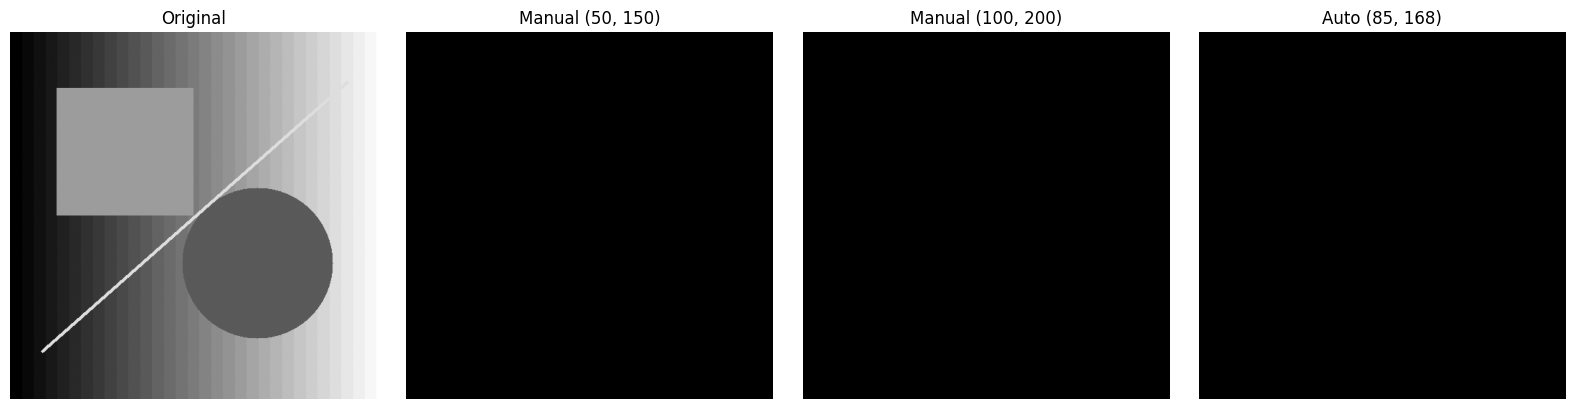

,image_name,method,low_threshold,high_threshold,edge_pixels,edge_ratio_percent
0,01_hinh_hoc_ro_net.png,Manual 50-150,50,150,3051,1.164
1,01_hinh_hoc_ro_net.png,Manual 100-200,100,200,3051,1.164
2,01_hinh_hoc_ro_net.png,Auto-Canny,164,255,3051,1.164
3,02_tuong_phan_thap.png,Manual 50-150,50,150,0,0.000
4,02_tuong_phan_thap.png,Manual 100-200,100,200,0,0.000
5,02_tuong_phan_thap.png,Auto-Canny,85,168,0,0.000


In [29]:
# Tạo hàm AutoCanny
def auto_canny(gray, sigma=0.33):
    median = np.median(gray)

    lower = int(max(0, (1.0 - sigma) * median))
    upper = int(min(255, (1.0 + sigma) * median))

    edges = cv2.Canny(gray, lower, upper)
    return edges, lower, upper


auto_results = []

# So sánh  với 2 bộ ngưỡng thủ công
for name, gray in images.items():
    manual_1 = cv2.Canny(gray, 50, 150)
    manual_2 = cv2.Canny(gray, 100, 200)
    automatic, low, high = auto_canny(gray)

    outputs = [
        ("Original", gray),
        ("Manual (50, 150)", manual_1),
        ("Manual (100, 200)", manual_2),
        (f"Auto ({low}, {high})", automatic)
    ]

    fig, axes = plt.subplots(1, 4, figsize=(16, 4))

    for ax, (title, output) in zip(axes, outputs):
        ax.imshow(output, cmap="gray")
        ax.set_title(title)
        ax.axis("off")

    plt.tight_layout()
    plt.savefig(
        FIGURE_DIR / f"auto_canny_{Path(name).stem}.png",
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()

    for method, output, lower, upper in [
        ("Manual 50-150", manual_1, 50, 150),
        ("Manual 100-200", manual_2, 100, 200),
        ("Auto-Canny", automatic, low, high)
    ]:
        auto_results.append({
            "image_name": name,
            "method": method,
            "low_threshold": lower,
            "high_threshold": upper,
            "edge_pixels": int(np.count_nonzero(output)),
            "edge_ratio_percent": round(
                float(np.count_nonzero(output) / output.size * 100), 3
            )
        })

auto_df = pd.DataFrame(auto_results)
display(auto_df)

auto_df.to_csv(
    FIGURE_DIR / "auto_canny_results.csv",
    index=False,
    encoding="utf-8-sig"
)

### Nhận xét kết quả

- **Ảnh 1 – Hình học rõ nét:** Cả hai cấu hình ngưỡng thủ công `(50, 150)` và `(100, 200)` đều phát hiện được các đường biên của hình vuông, hình tròn, tam giác và đường thẳng. Auto-Canny cũng cho kết quả tương tự. Bảng thống kê cho thấy cả ba phương pháp đều phát hiện 3.051 pixel biên, chiếm 1,164% tổng số pixel của ảnh.

- **Ảnh 2 – Độ tương phản thấp:** Cả hai cấu hình ngưỡng thủ công và Auto-Canny đều không phát hiện được pixel biên nào. Nguyên nhân có thể liên quan đến đặc điểm cường độ sáng và độ tương phản của ảnh khiến các đường biên không được phát hiện với những ngưỡng đã chọn.

- **So sánh các phương pháp:** Trên ảnh thứ nhất, ba phương pháp cho kết quả giống nhau theo số lượng pixel biên. Tuy nhiên, trên ảnh thứ hai, cả ba đều không phát hiện được đường biên. Điều này cho thấy Auto-Canny không phải lúc nào cũng thích ứng tốt với mọi loại ảnh chỉ bằng cách sử dụng giá trị trung vị cường độ sáng.

**Kết luận:** Hiệu quả của Canny phụ thuộc vào đặc điểm của ảnh và cách lựa chọn ngưỡng. Với ảnh có đường biên rõ ràng, các cấu hình đang thử nghiệm cho kết quả tương tự. Với ảnh có độ tương phản thấp, cần khảo sát thêm các ngưỡng hoặc phương pháp tiền xử lý để cải thiện kết quả.

### Trường hợp Auto-Canny chưa cho kết quả tốt

Dựa trên kết quả thực nghiệm, Auto-Canny chưa cải thiện được khả năng phát hiện biên trên ảnh có độ tương phản thấp.

- **Ảnh hình học rõ nét:** Auto-Canny tự động chọn ngưỡng `(164, 255)`. Kết quả phát hiện 3.051 pixel biên, tương đương hai cấu hình thủ công `(50, 150)` và `(100, 200)`. Trong trường hợp này, Auto-Canny không thể hiện ưu thế rõ rệt về số lượng pixel biên.

- **Ảnh có độ tương phản thấp:** Auto-Canny chọn ngưỡng `(85, 168)` nhưng không phát hiện được pixel biên nào. Hai cấu hình thủ công `(50, 150)` và `(100, 200)` cũng cho kết quả tương tự. Như vậy, Auto-Canny chưa xử lý hiệu quả ảnh này.

**Nguyên nhân và hạn chế:** Auto-Canny xác định ngưỡng dựa trên trung vị cường độ sáng của ảnh. Giá trị trung vị không phản ánh đầy đủ độ mạnh của đường biên hoặc sự khác biệt giữa biên thật và nhiễu. Vì vậy, ngưỡng tự động có thể chưa phù hợp với một số ảnh.

**Kết luận:** Auto-Canny giúp tự động lựa chọn ngưỡng, giảm thao tác thiết lập thủ công, nhưng không đảm bảo kết quả tốt hơn trong mọi trường hợp. Với ảnh có độ tương phản thấp, cần xem xét thêm các phương pháp tiền xử lý hoặc cách lựa chọn ngưỡng khác để cải thiện khả năng phát hiện biên.

## 7. Kiểm tra trên bộ dữ liệu 50 ảnh

Áp dụng cấu hình Baseline lên toàn bộ ảnh để so sánh kết quả phát hiện biên giữa các nhóm ảnh gốc và ảnh biến thể.

In [30]:
all_results = []

for path in image_paths:
    gray = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

    if gray is None:
        continue

    edges = canny(
        gray.astype(np.float32) / 255.0,
        sigma=BASELINE_SIGMA,
        low_threshold=BASELINE_LOW,
        high_threshold=BASELINE_HIGH
    )

    all_results.append({
        "image_name": path.name,
        "edge_pixels": int(np.count_nonzero(edges)),
        "edge_ratio_percent": round(float(edges.mean() * 100), 3),
        "mean_intensity": round(float(gray.mean()), 2),
        "std_intensity": round(float(gray.std()), 2)
    })

all_df = pd.DataFrame(all_results)
display(all_df)

all_df.to_csv(
    FIGURE_DIR / "all_50_images_results.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Số ảnh đã xử lý:", len(all_df))

,image_name,edge_pixels,edge_ratio_percent,mean_intensity,std_intensity
0,01_hinh_hoc_ro_net.png,3755,1.432,208.32,57.28
1,02_tuong_phan_thap.png,892,0.340,127.14,8.61
2,03_nhieu_gaussian.png,86956,33.171,201.51,59.49
3,04_anh_that_nhieu_chi_tiet.png,25934,9.893,129.06,73.64
4,05_dong_xu_phan_doan.png,12777,10.981,96.86,52.88
5,06_chan_dung_mau.png,26056,9.940,114.97,75.04
6,07_anh_bi_mo.png,3879,1.480,129.06,70.18
7,08_nhieu_doi_tuong.png,4320,1.648,203.71,54.75
8,09_tang_tuong_phan_01.png,3390,1.104,216.04,60.71
9,10_tang_tuong_phan_02.png,35016,11.398,219.11,58.09


Số ảnh đã xử lý: 50


## 9. Nhận xét kết quả trên bộ dữ liệu 50 ảnh

### 9.1. Mục đích

Áp dụng cùng một cấu hình Baseline Canny với `sigma = 1.0`, `low_threshold = 0.1` và `high_threshold = 0.2` cho toàn bộ 50 ảnh. Các chỉ số được sử dụng để đánh giá gồm số pixel biên (`edge_pixels`), tỷ lệ pixel biên (`edge_ratio_percent`), cường độ sáng trung bình (`mean_intensity`) và độ lệch chuẩn cường độ sáng (`std_intensity`).

### 9.2. Nhận xét từ kết quả

- **Ảnh có nhiễu:** Một số ảnh nhiễu Gaussian có tỷ lệ pixel biên cao, chẳng hạn `23_nhieu_gaussian_03.png` đạt 31.214%. Điều này cho thấy nhiễu có thể tạo ra nhiều biến đổi cường độ sáng và khiến Canny phát hiện thêm các đường biên không mong muốn.

- **Ảnh có độ tương phản thấp:** `18_giam_tuong_phan_04.png` có tỷ lệ pixel biên bằng 0%. Trong khi đó, `02_tuong_phan_thap.png` vẫn có tỷ lệ pixel biên là 0.340%. Kết quả cho thấy khả năng phát hiện biên có thể thay đổi tùy theo đặc điểm cụ thể của từng ảnh, ngay cả khi ảnh có độ tương phản thấp.

- **Ảnh bị làm mờ:** Các ảnh trong nhóm làm mờ Gaussian có tỷ lệ pixel biên dao động từ 1.089% đến 6.874%. Một số ảnh vẫn giữ được nhiều biên, trong khi những ảnh khác có ít biên hơn. Vì vậy, mức độ ảnh hưởng của việc làm mờ cần được đánh giá theo từng ảnh.

- **Ảnh có ánh sáng không đều:** Tỷ lệ pixel biên dao động từ 0.282% đến 8.737%. Sự khác biệt này cho thấy kết quả phát hiện biên không đồng nhất giữa các ảnh có điều kiện chiếu sáng khác nhau.

- **Ảnh có gradient và họa tiết:** Một số ảnh đạt tỷ lệ pixel biên cao, chẳng hạn `45_gradient_va_texture_01.png` đạt 29.749% và `49_gradient_va_texture_05.png` đạt 27.171%. Điều này có thể xuất phát từ các chi tiết hoặc biến đổi cường độ sáng được phát hiện như đường biên.

### 9.3. Kết luận

Kết quả khảo sát cho thấy cùng một cấu hình Baseline Canny tạo ra tỷ lệ pixel biên khác nhau trên các ảnh. Những ảnh có nhiều nhiễu hoặc họa tiết có thể tạo ra nhiều pixel biên, trong khi một số ảnh có độ tương phản thấp có thể không phát hiện được biên.

Tuy nhiên, tỷ lệ pixel biên chỉ phản ánh số lượng pixel được phân loại là biên, không trực tiếp thể hiện chất lượng phát hiện biên. Vì vậy, cần kết hợp quan sát ảnh kết quả với các thí nghiệm thay đổi sigma và ngưỡng Canny để đánh giá cấu hình phù hợp cho từng loại ảnh.

##  Hiển thị kết quả Canny trên 50 ảnh

Áp dụng cấu hình Baseline cho toàn bộ 50 ảnh trong bộ dữ liệu. Hiển thị ảnh gốc và ảnh biên tương ứng để quan sát sự khác biệt giữa các loại ảnh và điều kiện hình ảnh.

Sử dụng image_paths, BASELINE_SIGMA, BASELINE_LOW, BASELINE_HIGH và FIGURE_DIR đã tạo ở các bước trước.sử dụng image_paths, BASELINE_SIGMA, BASELINE_LOW, BASELINE_HIGH và FIGURE_DIR đã tạo ở các bước trước.

In [31]:
# Hiển thị ảnh gốc và kết quả Canny của toàn bộ 50 ảnh

all_edges = []

for path in image_paths:
    gray = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

    if gray is None:
        print(f"Không đọc được ảnh: {path.name}")
        continue

    edges = canny(
        gray.astype(np.float32) / 255.0,
        sigma=BASELINE_SIGMA,
        low_threshold=BASELINE_LOW,
        high_threshold=BASELINE_HIGH
    )

    all_edges.append((path.name, gray, edges))

print("Số ảnh đã xử lý:", len(all_edges))

Số ảnh đã xử lý: 50


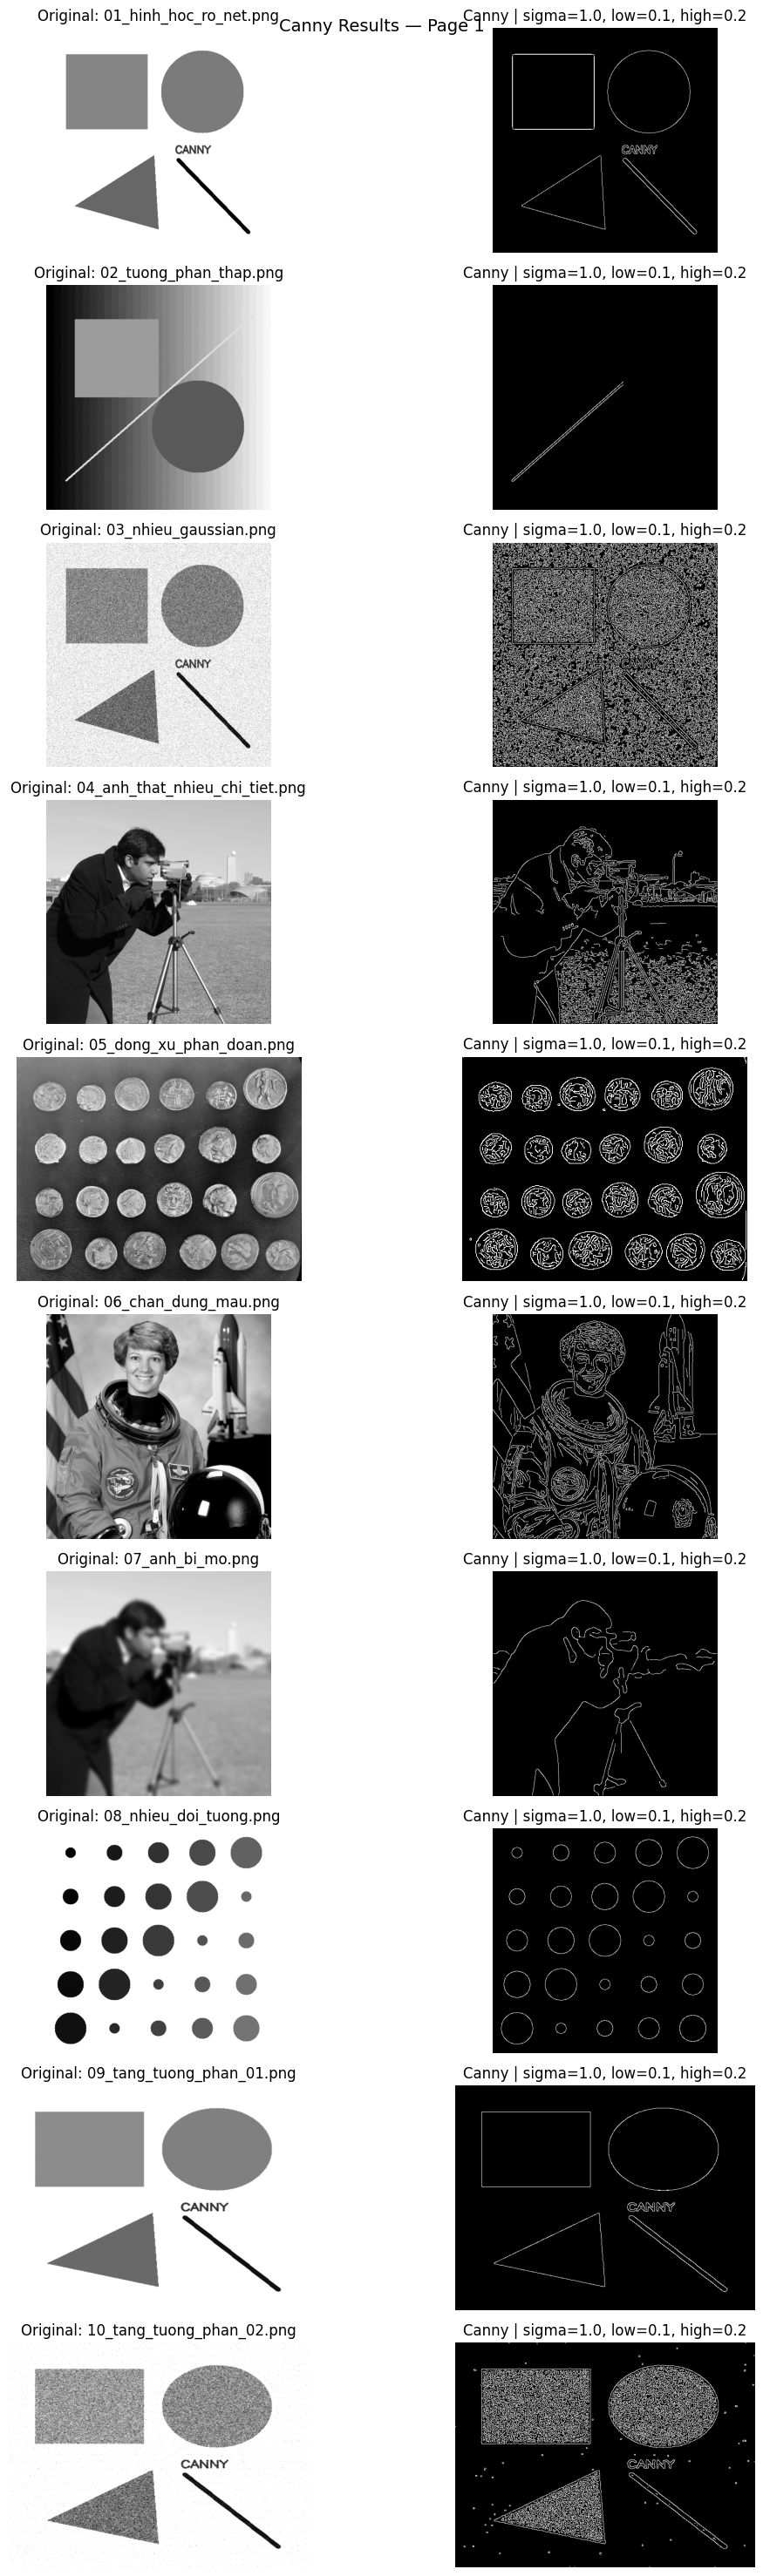

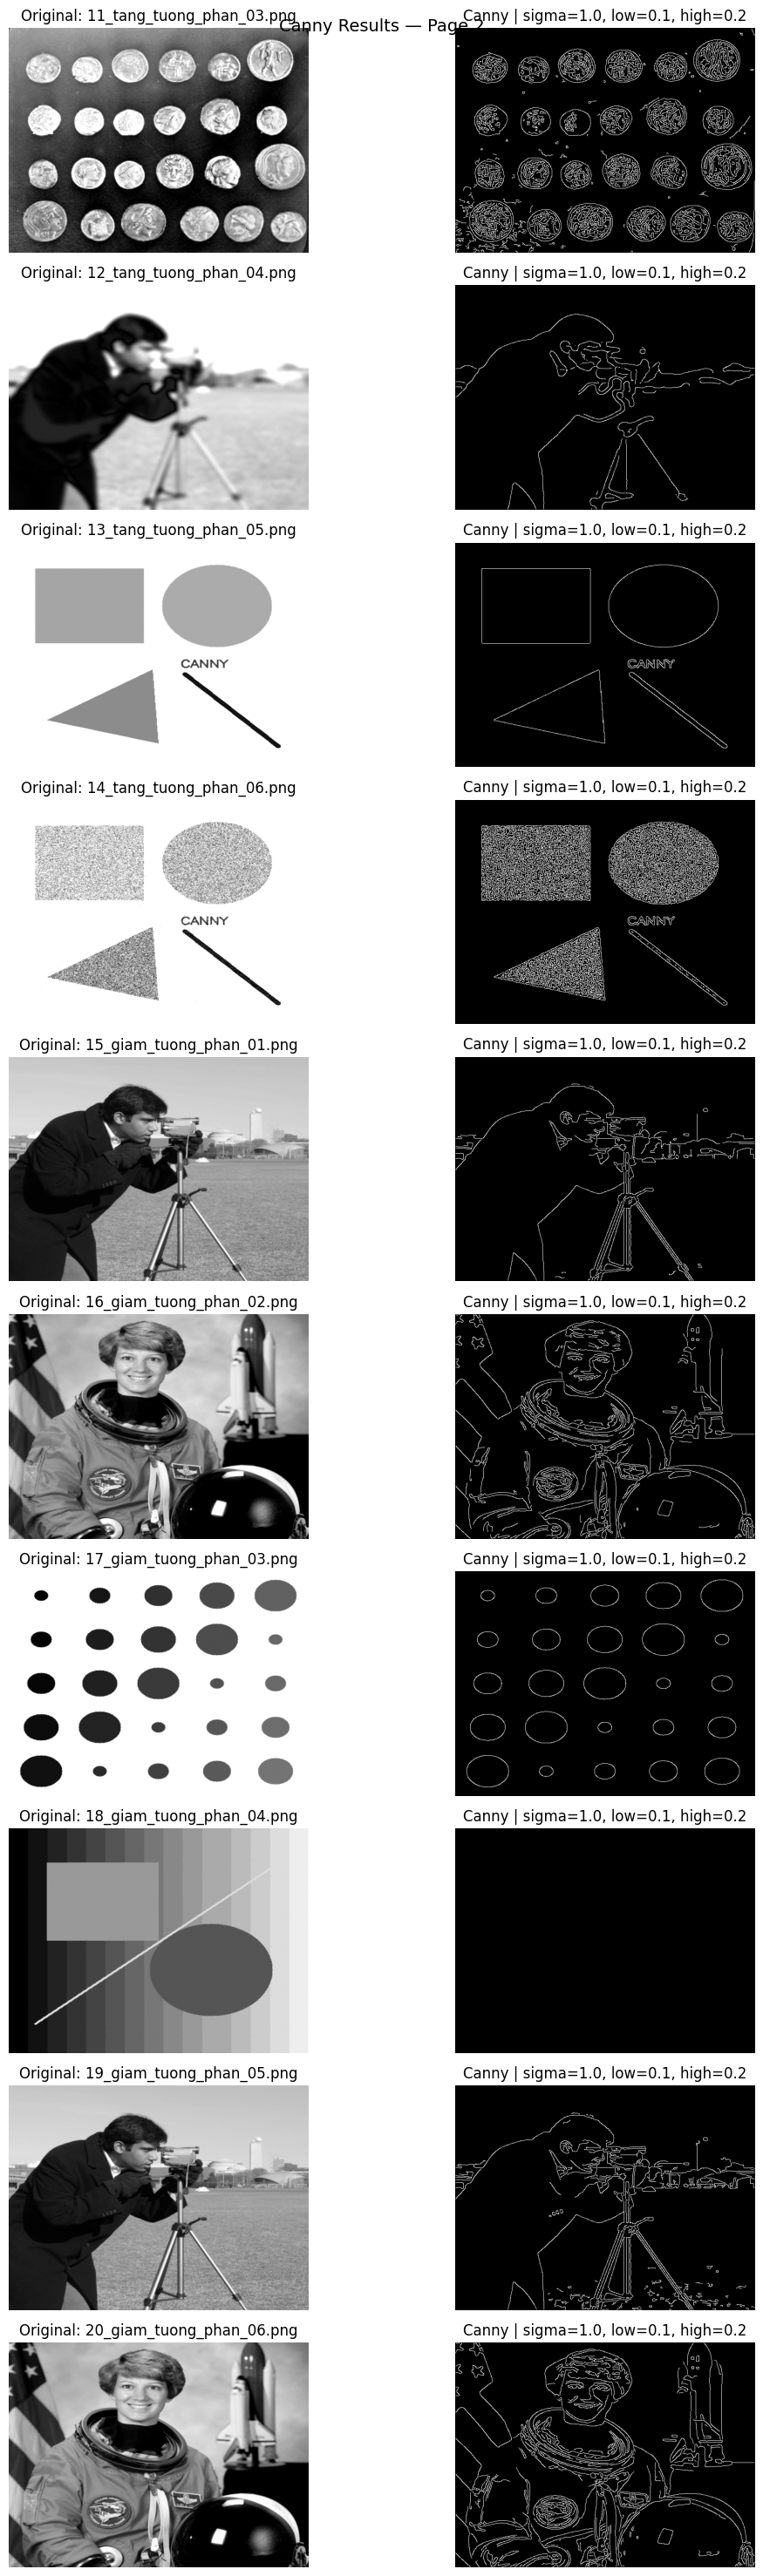

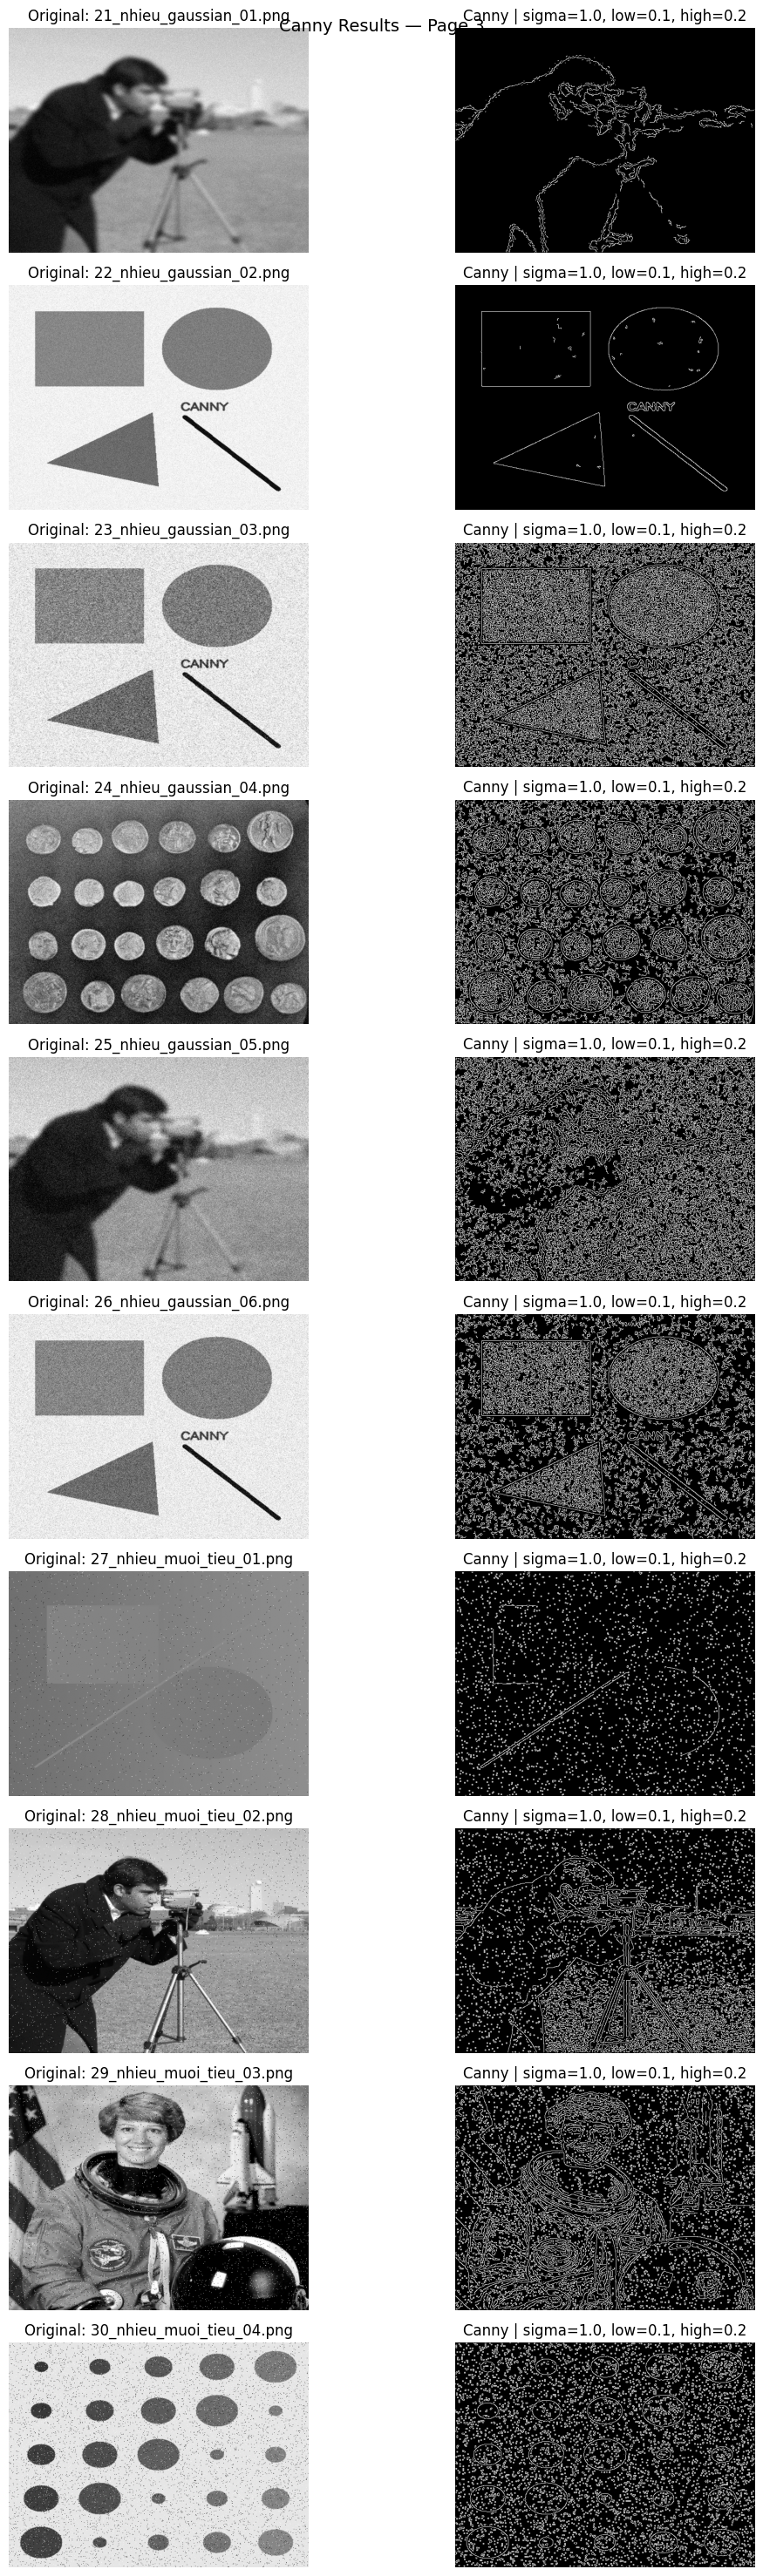

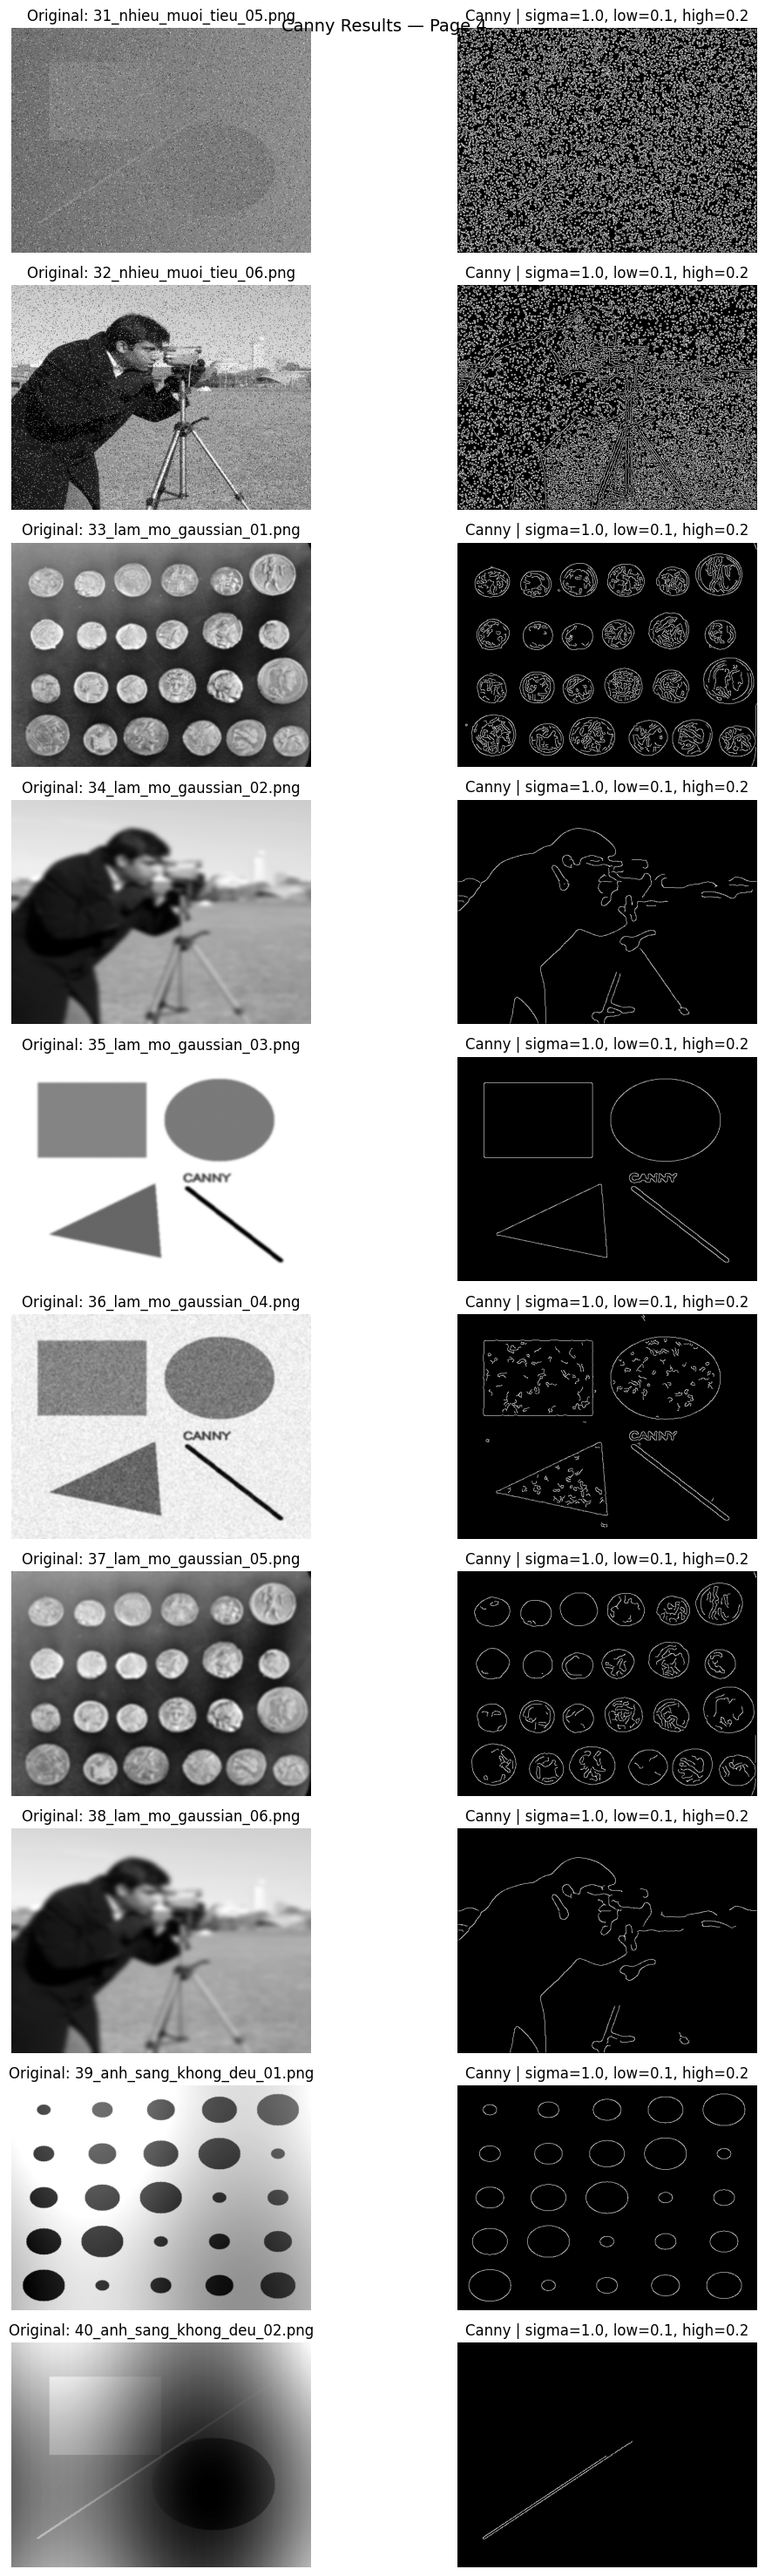

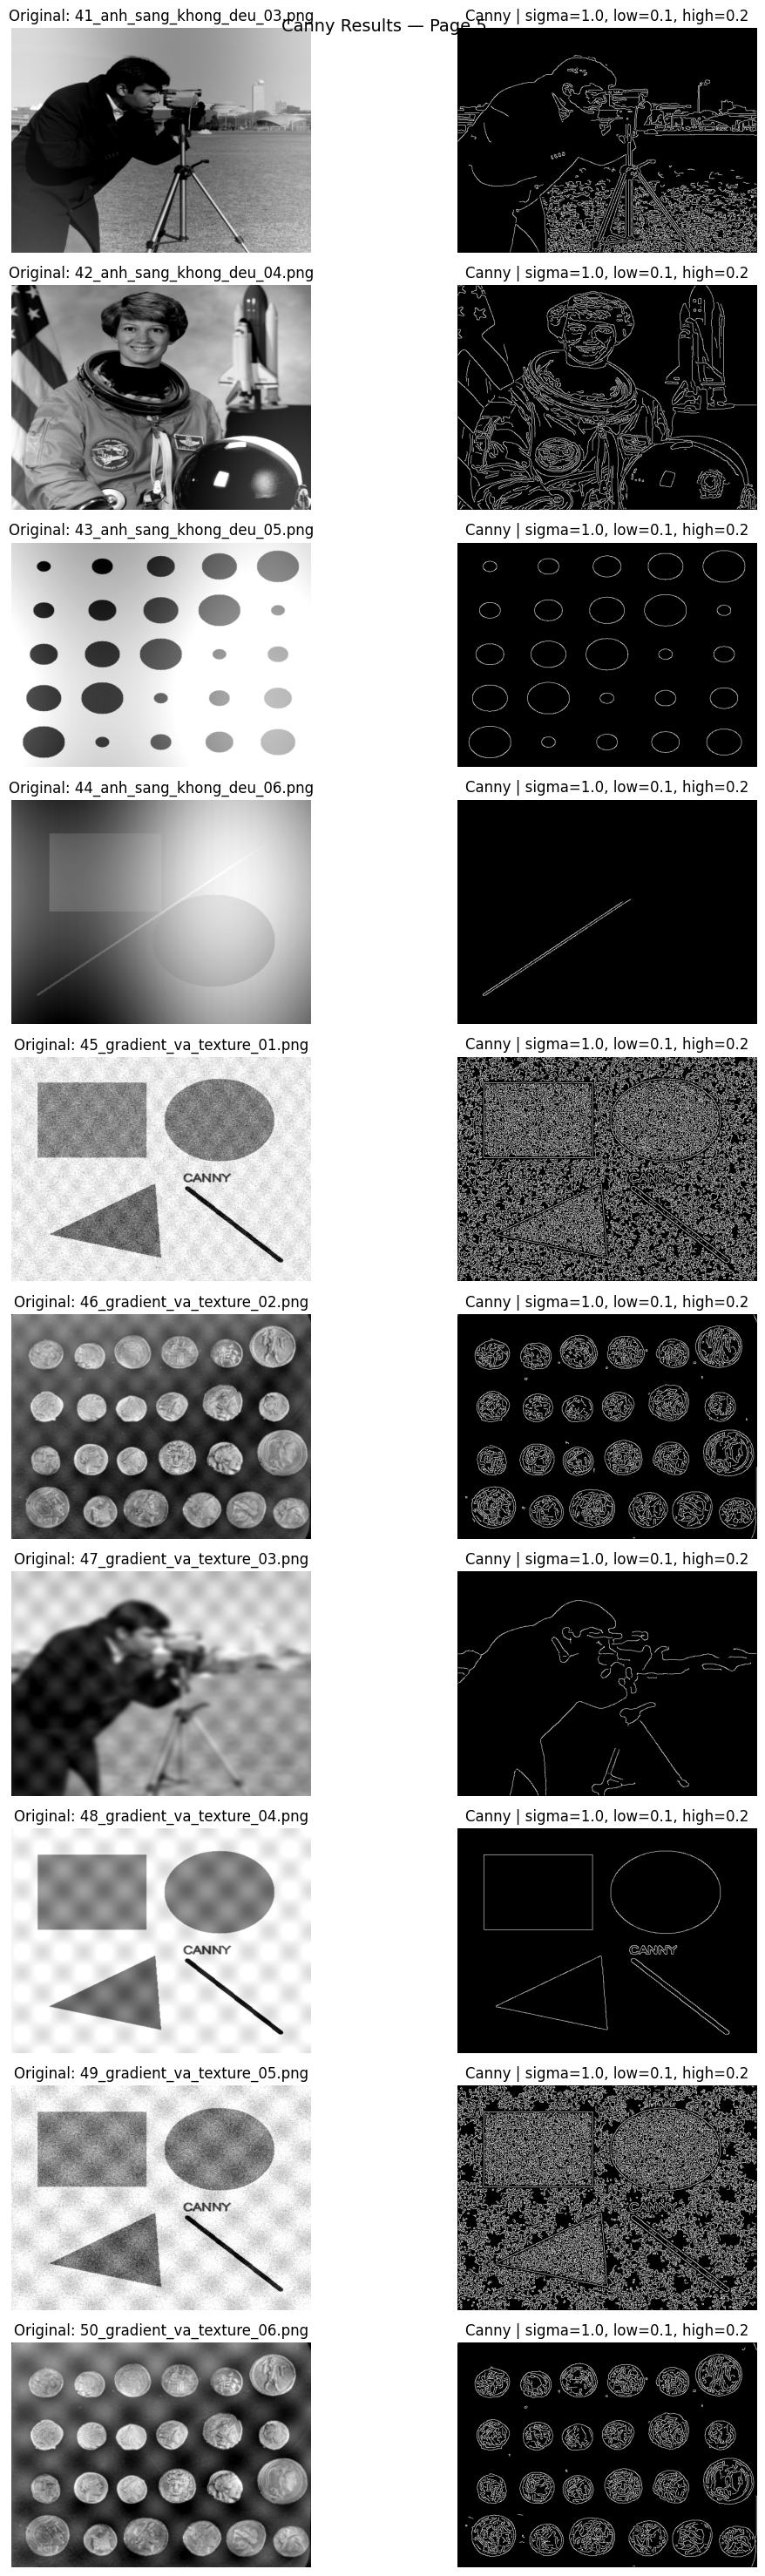

In [32]:
# Hiển thị 10 ảnh mỗi trang

IMAGES_PER_PAGE = 10

for start in range(0, len(all_edges), IMAGES_PER_PAGE):
    page_images = all_edges[start:start + IMAGES_PER_PAGE]

    fig, axes = plt.subplots(
        len(page_images), 2,
        figsize=(12, 3 * len(page_images)),
        squeeze=False
    )

    for row, (name, gray, edges) in enumerate(page_images):
        axes[row, 0].imshow(gray, cmap="gray")
        axes[row, 0].set_title(f"Original: {name}")
        axes[row, 0].axis("off")

        axes[row, 1].imshow(edges, cmap="gray")
        axes[row, 1].set_title(
            f"Canny | sigma={BASELINE_SIGMA}, "
            f"low={BASELINE_LOW}, high={BASELINE_HIGH}"
        )
        axes[row, 1].axis("off")

    page_number = start // IMAGES_PER_PAGE + 1
    fig.suptitle(f"Canny Results — Page {page_number}", fontsize=14)
    plt.tight_layout()

    plt.savefig(
        FIGURE_DIR / f"all_images_page_{page_number}.png",
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()

## Bảng tổng hợp tham số

Bảng dưới đây tổng hợp các cấu hình được sử dụng trong thí nghiệm Baseline, khảo sát sigma, khảo sát ngưỡng và Auto-Canny.

In [33]:
parameter_summary = pd.DataFrame([
    {
        "experiment": "Baseline",
        "sigma": 1.0,
        "low_threshold": 0.10,
        "high_threshold": 0.20
    },
    *[
        {
            "experiment": "Sigma",
            "sigma": s,
            "low_threshold": 0.10,
            "high_threshold": 0.20
        }
        for s in [0.8, 1.4, 2.2]
    ],
    *[
        {
            "experiment": "Threshold",
            "sigma": 1.0,
            "low_threshold": low,
            "high_threshold": high
        }
        for low, high in [
            (0.05, 0.15),
            (0.10, 0.20),
            (0.15, 0.30),
            (0.20, 0.40)
        ]
    ]
])

display(parameter_summary)

,experiment,sigma,low_threshold,high_threshold
0,Baseline,1.0,0.10,0.20
1,Sigma,0.8,0.10,0.20
2,Sigma,1.4,0.10,0.20
3,Sigma,2.2,0.10,0.20
4,Threshold,1.0,0.05,0.15
5,Threshold,1.0,0.10,0.20
6,Threshold,1.0,0.15,0.30
7,Threshold,1.0,0.20,0.40


## 9. Kết luận

- **Ảnh hình học rõ nét:** Khi thay đổi sigma và ngưỡng, kết quả phát hiện biên ít thay đổi. Tỷ lệ pixel biên ở Baseline là 1.432%.
- **Ảnh tương phản thấp:** Khi sigma tăng lên 1.4 và 2.2, kết quả không còn pixel biên. Khi tăng ngưỡng lên (0.15, 0.30), kết quả cũng không phát hiện được biên.
- **Auto-Canny:** Trên hai ảnh thử nghiệm, tỷ lệ pixel biên của Auto-Canny giống hai cấu hình ngưỡng thủ công. Tuy nhiên, với ảnh tương phản thấp, cả ba cấu hình đều không phát hiện được biên.
- **Kết luận chung:** Tham số phù hợp phụ thuộc vào đặc điểm của ảnh. Cần lựa chọn ngưỡng và sigma dựa trên kết quả thực tế, không thể dùng một cấu hình cho mọi ảnh.

Lưu ảnh

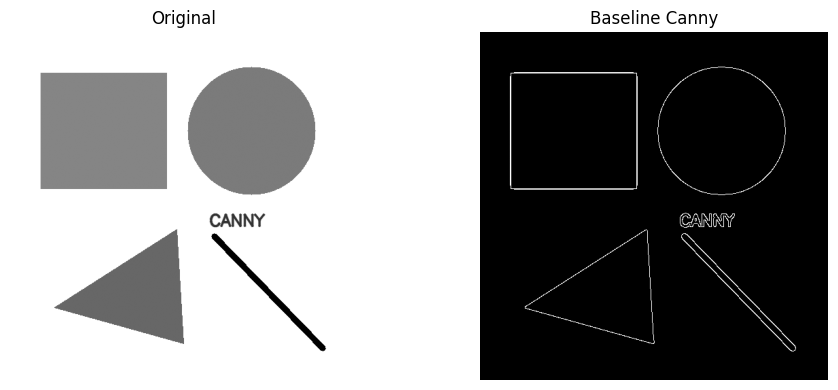

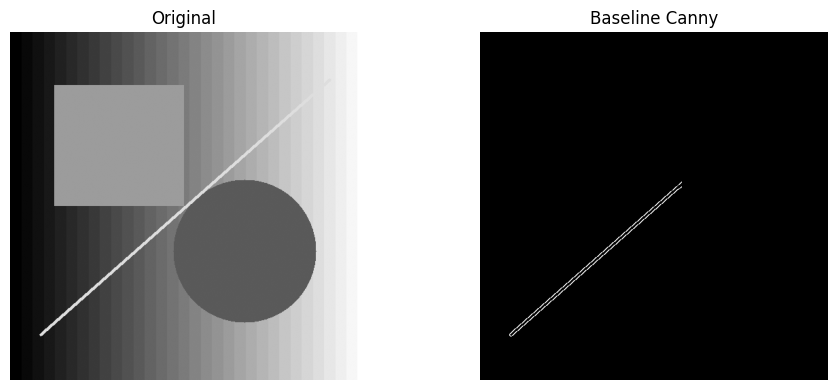

Đã lưu kết quả Baseline của 2 ảnh tại: C:\Users\Acer\Documents\Computer-Vision-Group-2\lab_2\result\figures\tv2_parameters


In [34]:
# Lưu kết quả Baseline của 2 ảnh thử nghiệm
for name, gray in images.items():
    edges = canny(
        gray.astype(np.float32) / 255.0,
        sigma=BASELINE_SIGMA,
        low_threshold=BASELINE_LOW,
        high_threshold=BASELINE_HIGH
    )

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    axes[0].imshow(gray, cmap="gray")
    axes[0].set_title("Original")
    axes[0].axis("off")

    axes[1].imshow(edges, cmap="gray")
    axes[1].set_title("Baseline Canny")
    axes[1].axis("off")

    plt.tight_layout()
    plt.savefig(
        FIGURE_DIR / f"baseline_{Path(name).stem}.png",
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

print("Đã lưu kết quả Baseline của 2 ảnh tại:", FIGURE_DIR)